# Topological Accessibility of Shopping Malls in Medellín
## Persistent Homology via Cubical Complexes — Proof of Concept

**Research question:** Can persistent homology reveal the spatial structure of accessibility to shopping malls, detecting service voids and fragmented access patterns that standard coverage metrics miss?

**Workflow:**
1. Load the Medellín street network (GraphML)
2. Divide the city into 100 m × 100 m grid cells
3. Locate shopping malls from OpenStreetMap
4. Compute walking times from each cell centroid to the nearest mall (OSRM public API)
5. Build a sublevel-set cubical filtration: $f(\text{cell}) = $ walking time to nearest mall
6. Compute $H_0$ and $H_1$ persistent homology using GUDHI
7. Visualise persistence diagrams, barcodes, and the filtration's spatial evolution

## 0 · Dependencies

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
import folium
from shapely.geometry import box, Point, Polygon
from shapely.ops import unary_union
import osmnx as ox
import networkx as nx
import requests
import time
import json
import gudhi
from gudhi import plot_persistence_barcode, plot_persistence_diagram
from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "graph_kernels").exists() and (candidate / "levelset_urban_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
CITY_PH_ROOT = REPO_ROOT / "15_min_city_ph"
FIGS_DIR = CITY_PH_ROOT / "figs"
FIGS_DIR.mkdir(parents=True, exist_ok=True)

print(f'NumPy   {np.__version__}')
print(f'GeoPandas {gpd.__version__}')
print(f'OSMnx   {ox.__version__}')
print(f'GUDHI   {gudhi.__version__}')
print('All imports OK ✓')

NumPy   1.26.4
GeoPandas 1.1.2
OSMnx   2.0.7
GUDHI   3.11.0
All imports OK ✓


## 1 · Load the Medellín Street Network

In [2]:
GRAPHML_PATH = CITY_PH_ROOT / 'medellin_drive_with_elevation.graphml'

print('Loading GraphML …')
G = ox.load_graphml(GRAPHML_PATH)
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)

print(f'Nodes: {len(nodes_gdf):,}   Edges: {len(edges_gdf):,}')
print(f'CRS   : {nodes_gdf.crs}')
bounds = nodes_gdf.total_bounds  # minx=min_lon, miny=min_lat, maxx=max_lon, maxy=max_lat
print(f'Bounds (lon/lat): lon=[{bounds[0]:.4f}, {bounds[2]:.4f}]  lat=[{bounds[1]:.4f}, {bounds[3]:.4f}]')

Loading GraphML …
Nodes: 15,207   Edges: 36,725
CRS   : epsg:4326
Bounds (lon/lat): lon=[-75.6445, -75.5270]  lat=[6.1773, 6.3121]


## 2 · Divide Medellín into 100 m × 100 m Grid Cells

We reproject to a metric CRS (UTM zone 18N, EPSG:32618) to create the grid in metres, then project back to WGS-84 for downstream work.

In [3]:
CELL_SIZE_M = 100  # metres
UTM_CRS = 'EPSG:32618'  # UTM zone 18N covers Medellín
WGS84   = 'EPSG:4326'

# ── Build a convex-hull polygon of the road network (WGS-84 → UTM) ──────────
network_poly_wgs = gpd.GeoSeries(
    [unary_union(nodes_gdf.geometry)], crs=WGS84
).convex_hull
network_poly_utm = network_poly_wgs.to_crs(UTM_CRS)

# ── Generate regular 100 m grid covering the bounding box ───────────────────
minx, miny, maxx, maxy = network_poly_utm.total_bounds

xs = np.arange(minx, maxx, CELL_SIZE_M)
ys = np.arange(miny, maxy, CELL_SIZE_M)

grid_cells_utm = []
for x in xs:
    for y in ys:
        cell = box(x, y, x + CELL_SIZE_M, y + CELL_SIZE_M)
        grid_cells_utm.append(cell)

grid_gdf = gpd.GeoDataFrame({'geometry': grid_cells_utm}, crs=UTM_CRS)

# ── Keep only cells that intersect the city polygon ─────────────────────────
city_poly_utm = network_poly_utm.iloc[0]
mask = grid_gdf.intersects(city_poly_utm)
grid_gdf = grid_gdf[mask].reset_index(drop=True)

# ── Add centroid coords in WGS-84 for routing ────────────────────────────────
grid_gdf['centroid_utm'] = grid_gdf.geometry.centroid
centroids_wgs = (
    gpd.GeoDataFrame(geometry=grid_gdf['centroid_utm'], crs=UTM_CRS)
    .to_crs(WGS84)
    .geometry
)
grid_gdf['centroid_lon'] = centroids_wgs.x
grid_gdf['centroid_lat'] = centroids_wgs.y

# ── Grid index bookkeeping (row/col for cubical complex) ────────────────────
n_cols = len(xs)
n_rows = len(ys)

print(f'Grid cells (before city clip): {len(xs) * len(ys):,}')
print(f'Grid cells (within city hull): {len(grid_gdf):,}')
print(f'Grid dimensions: {n_rows} rows × {n_cols} cols')

Grid cells (before city clip): 19,370
Grid cells (within city hull): 13,150
Grid dimensions: 149 rows × 130 cols


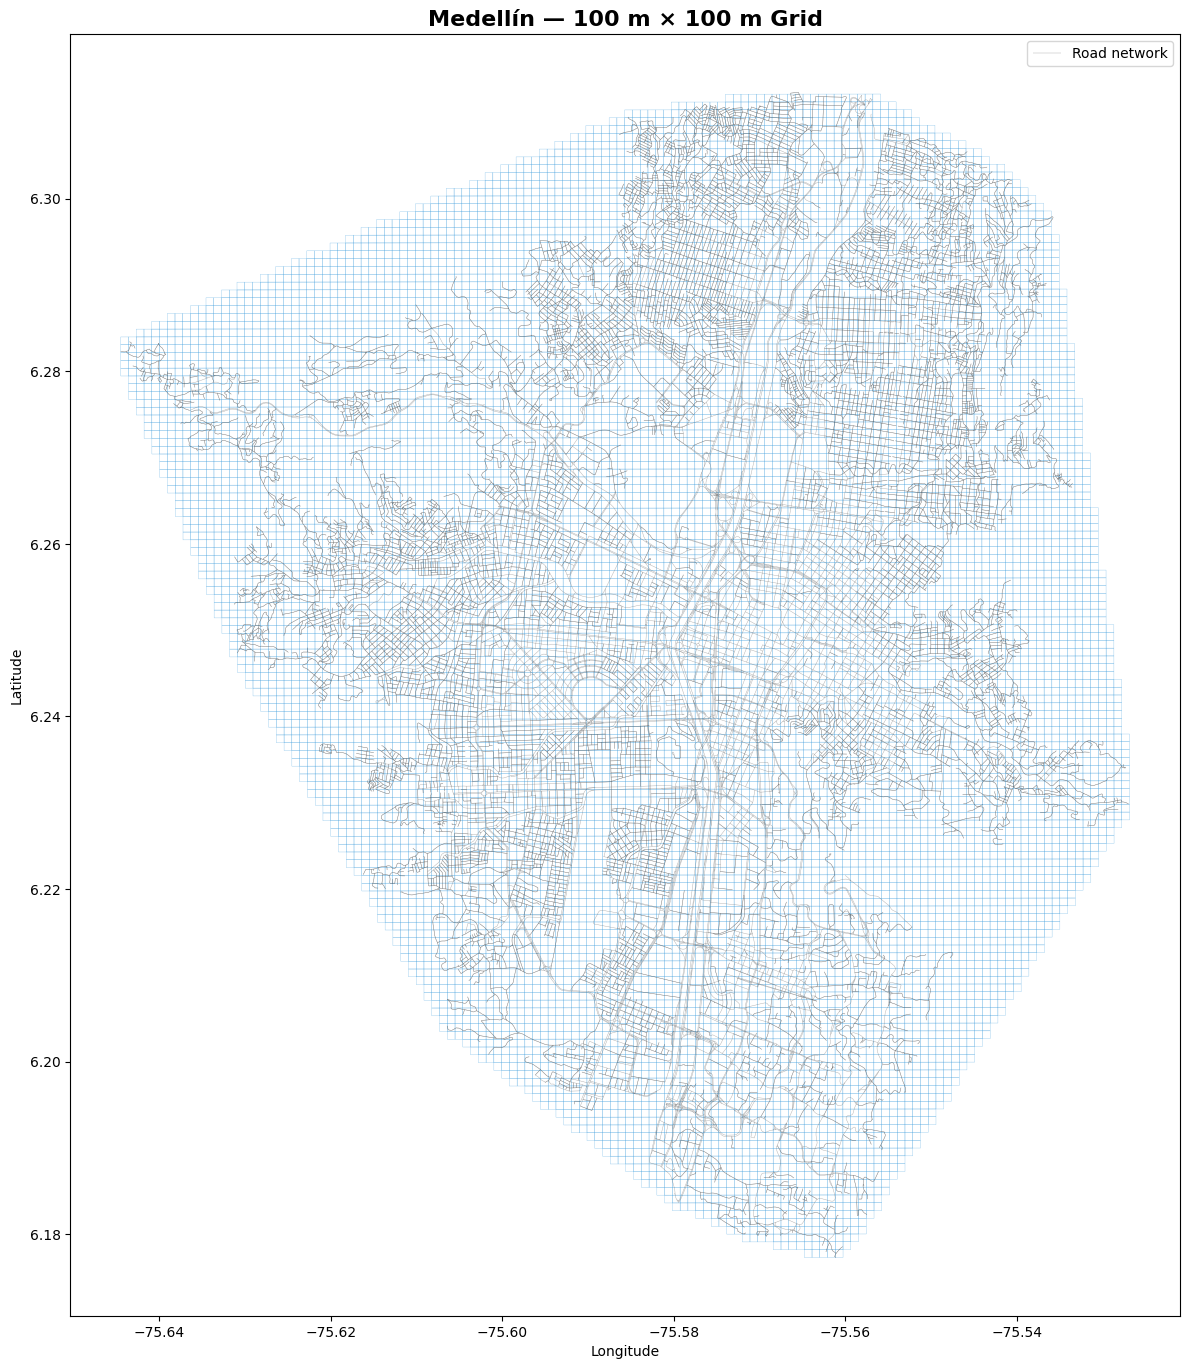

Saved fig01_grid.png


In [4]:
# ── Plot: 100 m grid over the Medellín road network ─────────────────────────
fig, ax = plt.subplots(figsize=(12, 14))

# Road network edges (WGS-84)
edges_gdf.plot(ax=ax, linewidth=0.3, color='#555555', alpha=0.5, label='Road network')

# Grid cells (reproject back to WGS-84 for consistent axes)
grid_wgs = grid_gdf.to_crs(WGS84)
grid_wgs.plot(ax=ax, facecolor='none', edgecolor='#3498db', linewidth=0.25, alpha=0.6, label='100 m cells')

ax.set_title('Medellín — 100 m × 100 m Grid', fontsize=16, fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig01_grid.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved fig01_grid.png')

## 3 · Shopping Mall Locations

We fetch mall locations directly from OpenStreetMap via the Overpass API, replicating the query from `centros_comerciales.ipynb`.

In [7]:
def fetch_malls_osm(
    bbox=(6.14, -75.72, 6.36, -75.45),
    retries=3, delay=10
):
    """Query Overpass API for shopping malls in bbox (min_lat, min_lon, max_lat, max_lon)."""
    query = f"""
[out:json][timeout:60];
(
  nwr["shop"="mall"]({bbox[0]},{bbox[1]},{bbox[2]},{bbox[3]});
  nwr["building"="retail"]({bbox[0]},{bbox[1]},{bbox[2]},{bbox[3]});
);
out center tags;
"""
    url = 'https://overpass-api.de/api/interpreter'
    for attempt in range(retries):
        try:
            r = requests.post(url, data={'data': query},
                              headers={'User-Agent': 'medellin-ph-research/1.0'},
                              timeout=90)
            r.raise_for_status()
            data = r.json()
            break
        except Exception as e:
            print(f'  Attempt {attempt+1} failed: {e}')
            time.sleep(delay)
    else:
        raise RuntimeError('Could not fetch mall data from Overpass after retries.')

    rows = []
    for el in data.get('elements', []):
        tags = el.get('tags', {})
        lat = el.get('lat') or el.get('center', {}).get('lat')
        lon = el.get('lon') or el.get('center', {}).get('lon')
        if lat is None or lon is None:
            continue
        rows.append({
            'osm_id': el.get('id'),
            'name': tags.get('name'),
            'lat': float(lat),
            'lon': float(lon),
            'shop': tags.get('shop'),
            'building': tags.get('building'),
        })

    df = pd.DataFrame(rows)
    df = df.dropna(subset=['name', 'lat', 'lon'])
    df = df.drop_duplicates(subset=['name', 'lat', 'lon']).reset_index(drop=True)
    return df


print('Fetching mall locations from OpenStreetMap …')
malls_df = fetch_malls_osm()
print(f'Found {len(malls_df)} malls/retail buildings with names')
malls_df[['name','lat','lon','shop','building']].head(10)

Fetching mall locations from OpenStreetMap …
Found 140 malls/retail buildings with names


,name,lat,lon,shop,building
0,Mall Santa Maria Rodeo Alto,6.202849,-75.601624,mall,None
1,Interplaza,6.212770,-75.559043,mall,None
2,Verona Mall,6.206620,-75.560113,mall,None
3,Complex Los Balsos,6.186235,-75.562213,mall,None
4,Centro Comercial El Diamante,6.260731,-75.589770,mall,None
5,Mall Plaza,6.200493,-75.563939,mall,None
6,Automall Santa María de Las Vegas,6.192809,-75.579491,mall,None
7,Mall Itagüí,6.172985,-75.610159,mall,None
8,Centro Comercial La Mota,6.214907,-75.597360,mall,None
9,Cristalida,6.238827,-75.604258,mall,None


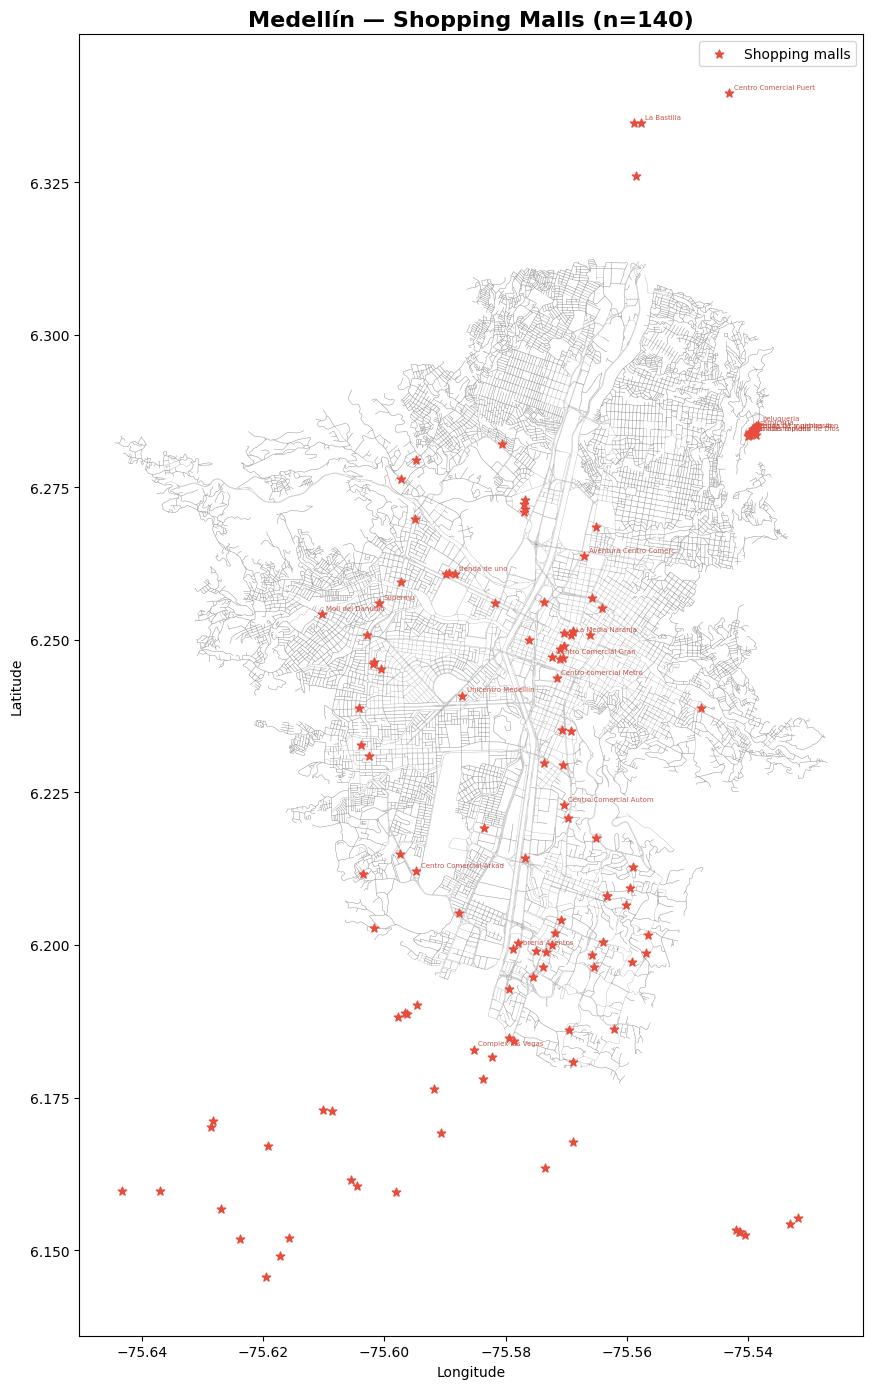

Saved fig02_malls.png


In [8]:
# ── Convert to GeoDataFrame ───────────────────────────────────────────────────
malls_gdf = gpd.GeoDataFrame(
    malls_df,
    geometry=gpd.points_from_xy(malls_df['lon'], malls_df['lat']),
    crs=WGS84
)

# ── Plot: Mall locations over road network ───────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 14))

edges_gdf.plot(ax=ax, linewidth=0.3, color='#777777', alpha=0.5)
malls_gdf.plot(
    ax=ax, color='#e74c3c', markersize=40,
    marker='*', zorder=5, label='Shopping malls'
)

# Label a subset of malls to avoid clutter
for _, row in malls_gdf.sample(min(20, len(malls_gdf)), random_state=42).iterrows():
    ax.annotate(
        row['name'][:22], xy=(row['lon'], row['lat']),
        xytext=(3, 3), textcoords='offset points',
        fontsize=5, color='#c0392b', alpha=0.85
    )

ax.set_title(f'Medellín — Shopping Malls (n={len(malls_gdf)})', fontsize=16, fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig02_malls.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig02_malls.png')

## 4 · Compute Walking Times to Nearest Mall

We use the **OSRM public API** (Project-OSRM) table endpoint with the `foot` profile.  
The API accepts a list of coordinates; we supply grid-cell centroids as *sources* and mall locations as *destinations*, and it returns a duration matrix (seconds).  

To stay within the public API's rate limits we send batches of ≤ 150 source cells at a time.

In [23]:
# ── Routing engine: Valhalla (valhalla1.openstreetmap.de) ───────────────────
#
# WHY NOT OSRM public (router.project-osrm.org):
#   The public server advertises a /table/v1/foot endpoint but silently falls
#   back to the car profile, returning ~37 km/h speeds instead of ~5 km/h.
#   Confirmed: a 1 477 m trip is reported as 142 s → 37.4 km/h.
#
# Valhalla's `pedestrian` costing gives ~4.7 km/h, which is correct.
# The /sources_to_targets endpoint returns a full origin–destination matrix
# in one POST request — no OSRM coordinate-string gymnastics needed.

VALHALLA_BASE = 'https://valhalla1.openstreetmap.de'
BATCH_SIZE    = 15   # sources per request (Valhalla handles 100 easily in <5 s)
DELAY_S       = 1.5   # polite pause between batches
MAX_RETRIES   = 4

def valhalla_matrix(src_lons, src_lats, dst_lons, dst_lats):
    """
    Call Valhalla /sources_to_targets.
    Returns a (n_src,) array of *seconds* to the nearest destination.
    Unreachable pairs are returned as NaN.
    """
    payload = {
        "sources":  [{"lon": float(lo), "lat": float(la)}
                     for lo, la in zip(src_lons, src_lats)],
        "targets":  [{"lon": float(lo), "lat": float(la)}
                     for lo, la in zip(dst_lons, dst_lats)],
        "costing":  "pedestrian",
    }
    for attempt in range(MAX_RETRIES):
        try:
            r = requests.post(
                f"{VALHALLA_BASE}/sources_to_targets",
                json=payload,
                headers={"Content-Type": "application/json"},
                timeout=60,
            )
            r.raise_for_status()
            data = r.json()
            rows = data["sources_to_targets"]   # list[list[{time, distance}|null]]
            out = np.full(len(src_lons), np.nan)
            for i, row in enumerate(rows):
                valid = [c["time"] for c in row
                         if c is not None and c.get("time") is not None]
                if valid:
                    out[i] = min(valid)
            return out          # seconds
        except Exception as e:
            wait = DELAY_S * (2 ** attempt)
            print(f"    Retry {attempt+1}/{MAX_RETRIES} — {e} — waiting {wait:.1f}s")
            time.sleep(wait)
    return np.full(len(src_lons), np.nan)


# ── Preflight sanity check ───────────────────────────────────────────────────
_test = valhalla_matrix(
    [-75.5700], [6.2500],
    [-75.5750], [6.2550],
)
_speed = (1477.5 / _test[0]) * 3.6 if not np.isnan(_test[0]) else float('nan')
print(f"Sanity check: {_test[0]:.1f} s for ~1 477 m  →  {_speed:.1f} km/h  (expected ≈ 4–5 km/h)")
assert 3.0 < _speed < 7.0, f"Speed {_speed:.1f} km/h is implausible — check routing engine!"
print("Routing engine check passed ✓")


Sanity check: 792.0 s for ~1 477 m  →  6.7 km/h  (expected ≈ 4–5 km/h)
Routing engine check passed ✓


In [24]:
# ── Compute walking times for all grid cells ─────────────────────────────────
mall_lons = malls_df['lon'].tolist()
mall_lats = malls_df['lat'].tolist()
n_malls   = len(mall_lons)

print(f'Computing walking times for {len(grid_gdf):,} cells → {n_malls} malls …')
print(f'Batch size: {BATCH_SIZE} | estimated batches: {int(np.ceil(len(grid_gdf)/BATCH_SIZE))}')
print(f'Using: Valhalla pedestrian routing (valhalla1.openstreetmap.de)\n')

all_times_s = np.full(len(grid_gdf), np.nan)
n_batches   = int(np.ceil(len(grid_gdf) / BATCH_SIZE))

for b in range(n_batches):
    start = b * BATCH_SIZE
    end   = min(start + BATCH_SIZE, len(grid_gdf))
    batch = grid_gdf.iloc[start:end]

    times_s = valhalla_matrix(
        batch['centroid_lon'].tolist(),
        batch['centroid_lat'].tolist(),
        mall_lons,
        mall_lats,
    )
    all_times_s[start:end] = times_s

    if (b + 1) % 10 == 0 or b == n_batches - 1:
        pct    = 100 * (b + 1) / n_batches
        nan_ct = np.isnan(all_times_s[:end]).sum()
        done   = end
        sample = all_times_s[:done]
        valid  = sample[~np.isnan(sample)]
        med    = np.median(valid) / 60 if len(valid) else float('nan')
        print(f'  Batch {b+1:4d}/{n_batches} ({pct:5.1f}%) | NaN: {nan_ct:4d} | '
              f'median so far: {med:.1f} min')

    time.sleep(DELAY_S)

# ── Convert to minutes and attach to grid ────────────────────────────────────
grid_gdf['walk_time_s']   = all_times_s
grid_gdf['walk_time_min'] = all_times_s / 60.0

n_nan = grid_gdf['walk_time_min'].isna().sum()
print(f'\nDone.  NaN cells: {n_nan} ({100*n_nan/len(grid_gdf):.1f}%)')
print(grid_gdf['walk_time_min'].describe().round(2))


Computing walking times for 13,150 cells → 140 malls …
Batch size: 15 | estimated batches: 877
Using: Valhalla pedestrian routing (valhalla1.openstreetmap.de)

  Batch   10/877 (  1.1%) | NaN:    0 | median so far: 71.3 min
  Batch   20/877 (  2.3%) | NaN:    0 | median so far: 65.7 min
  Batch   30/877 (  3.4%) | NaN:    0 | median so far: 58.9 min
  Batch   40/877 (  4.6%) | NaN:    0 | median so far: 56.5 min
  Batch   50/877 (  5.7%) | NaN:    0 | median so far: 51.9 min
  Batch   60/877 (  6.8%) | NaN:    0 | median so far: 48.6 min
  Batch   70/877 (  8.0%) | NaN:    0 | median so far: 47.5 min
  Batch   80/877 (  9.1%) | NaN:    0 | median so far: 46.1 min
  Batch   90/877 ( 10.3%) | NaN:    0 | median so far: 43.8 min
  Batch  100/877 ( 11.4%) | NaN:    0 | median so far: 42.1 min
  Batch  110/877 ( 12.5%) | NaN:    0 | median so far: 40.7 min
  Batch  120/877 ( 13.7%) | NaN:    0 | median so far: 39.5 min
  Batch  130/877 ( 14.8%) | NaN:    0 | median so far: 38.0 min
  Batch 

In [25]:
# ── Fill unreachable cells with a large value ────────────────────────────────
# Cells the OSRM foot router cannot reach (off-network, water, etc.) get
# a sentinel value larger than the filtration range so they stay "inactive".
SENTINEL = 120.0   # 120 minutes — well beyond any realistic threshold

grid_gdf['walk_time_min_filled'] = grid_gdf['walk_time_min'].fillna(SENTINEL)

print('Walking-time distribution (minutes):')
pcts = [0, 5, 10, 15, 20, 25, 30, 45, 60]
for p in pcts:
    v = grid_gdf['walk_time_min_filled'].quantile(p/100)
    print(f'  {p:3d}th pctile: {v:.1f} min')

Walking-time distribution (minutes):
    0th pctile: 0.0 min
    5th pctile: 3.9 min
   10th pctile: 5.7 min
   15th pctile: 7.1 min
   20th pctile: 8.5 min
   25th pctile: 9.9 min
   30th pctile: 11.2 min
   45th pctile: 15.8 min
   60th pctile: 23.6 min


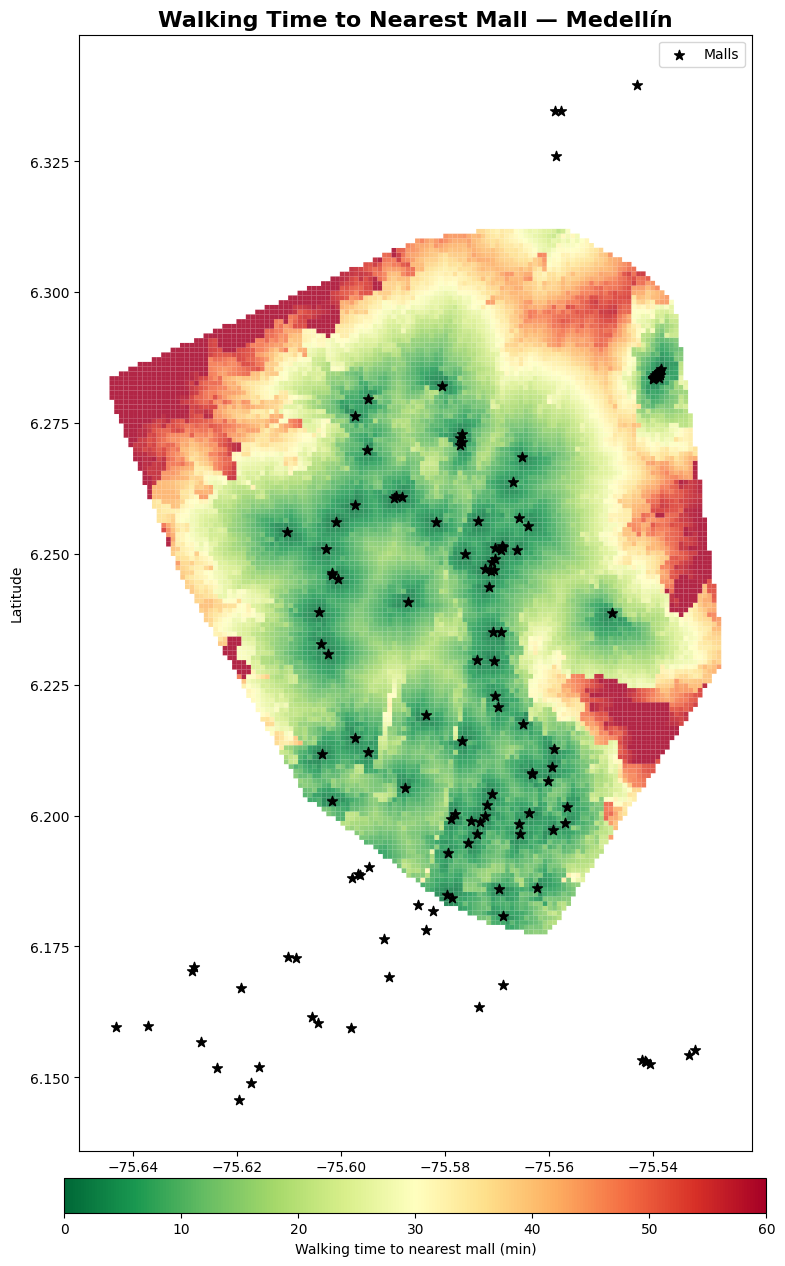

Saved fig03_walking_time.png


In [26]:
# ── Plot: Walking-time accessibility map ─────────────────────────────────────
grid_wgs = grid_gdf.to_crs(WGS84).copy()
grid_wgs['walk_time_min_filled'] = grid_gdf['walk_time_min_filled'].values

fig, ax = plt.subplots(figsize=(12, 14))

cmap = plt.get_cmap('RdYlGn_r')
vmax = 60
grid_wgs.plot(
    column='walk_time_min_filled',
    ax=ax,
    cmap=cmap,
    vmin=0, vmax=vmax,
    linewidth=0,
    alpha=0.85,
    legend=True,
    legend_kwds={
        'label': 'Walking time to nearest mall (min)',
        'orientation': 'horizontal',
        'shrink': 0.6,
        'pad': 0.02
    }
)
malls_gdf.plot(ax=ax, color='black', markersize=55, marker='*', zorder=6, label='Malls')

ax.set_title('Walking Time to Nearest Mall — Medellín', fontsize=16, fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig03_walking_time.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig03_walking_time.png')

In [16]:
test = requests.get(
    "http://router.project-osrm.org/route/v1/foot/"
    "-75.5700,6.2500;-75.5750,6.2550?overview=false",
    timeout=30
)
print(test.status_code)
print(test.text[:1000])

200
{"code":"Ok","routes":[{"legs":[{"steps":[],"weight":142.2,"summary":"","duration":142.2,"distance":1477.5}],"weight_name":"routability","weight":142.2,"duration":142.2,"distance":1477.5}],"waypoints":[{"hint":"OWRcg____38KAAAAKgAAAHkAAAAUAAAADNJdQRcAJkIJugdDCufLQQoAAAAqAAAAeQAAABQAAADUkQAAWuV--4RfXwCw5H77EF5fAA4AbxIAAAAA","location":[-75.56983,6.250372],"name":"Calle 50","distance":45.2356174},{"hint":"ygxog2mhSIdQAAAAHAAAAC0AAAAAAAAAsvUFQp1eN0EBbpZBAAAAAFAAAAAcAAAALQAAAAAAAADUkQAAgdF--ytyXwAo0X77mHFfAAQAzxIAAAAA","location":[-75.574911,6.255147],"name":"","distance":19.00689068}]}


## 5 · Build the Cubical Complex Filtration

### Conceptual setup

We construct a **sublevel-set filtration** on a regular 2-D grid:

$$f(\text{cell}) = \text{walking time to nearest mall (minutes)}$$

At threshold $t$, we include all cells with $f(\text{cell}) \le t$:

$$A_t = \{\text{cell} : f(\text{cell}) \le t\}$$

GUDHI's `CubicalComplex` takes the grid as a 2-D array where each entry is the *filtration value* of the corresponding top-dimensional cell (a 2-D square). It automatically derives the filtration values of the lower-dimensional faces (edges, vertices) via the lower-star rule.

The **key topological features** we interpret:
- **$H_0$** (connected components): accessibility *islands* — disconnected pockets of access
- **$H_1$** (loops / holes): service *voids* — regions of poor access surrounded by accessible areas

In [27]:
# ── Build a 2-D grid array aligned with the (row, col) UTM grid ──────────────
# We need to assign each grid cell its (row, col) index so we can fill
# a 2-D matrix for the cubical complex.

xs_arr = np.arange(minx, maxx, CELL_SIZE_M)
ys_arr = np.arange(miny, maxy, CELL_SIZE_M)

# Recompute cell indices in the full (n_rows × n_cols) grid
# centroids in UTM
cx_utm = grid_gdf['centroid_utm'].apply(lambda g: g.x).values
cy_utm = grid_gdf['centroid_utm'].apply(lambda g: g.y).values

col_idx = ((cx_utm - minx) / CELL_SIZE_M).astype(int)
row_idx = ((cy_utm - miny) / CELL_SIZE_M).astype(int)

col_idx = np.clip(col_idx, 0, len(xs_arr) - 1)
row_idx = np.clip(row_idx, 0, len(ys_arr) - 1)

grid_gdf['col_idx'] = col_idx
grid_gdf['row_idx'] = row_idx

# ── Fill the 2-D filtration matrix ───────────────────────────────────────────
# Cells outside the city boundary are set to SENTINEL.
filtration_matrix = np.full((len(ys_arr), len(xs_arr)), SENTINEL)

for idx, row in grid_gdf.iterrows():
    r = int(row['row_idx'])
    c = int(row['col_idx'])
    filtration_matrix[r, c] = row['walk_time_min_filled']

print(f'Filtration matrix shape: {filtration_matrix.shape}  ({filtration_matrix.shape[0] * filtration_matrix.shape[1]:,} cells)')
print(f'Values in [0, {filtration_matrix.max():.1f}] min')
print(f'Cells ≤ 15 min: {(filtration_matrix <= 15).sum():,}')
print(f'Cells ≤ 30 min: {(filtration_matrix <= 30).sum():,}')

Filtration matrix shape: (149, 130)  (19,370 cells)
Values in [0, 120.0] min
Cells ≤ 15 min: 5,660
Cells ≤ 30 min: 9,047


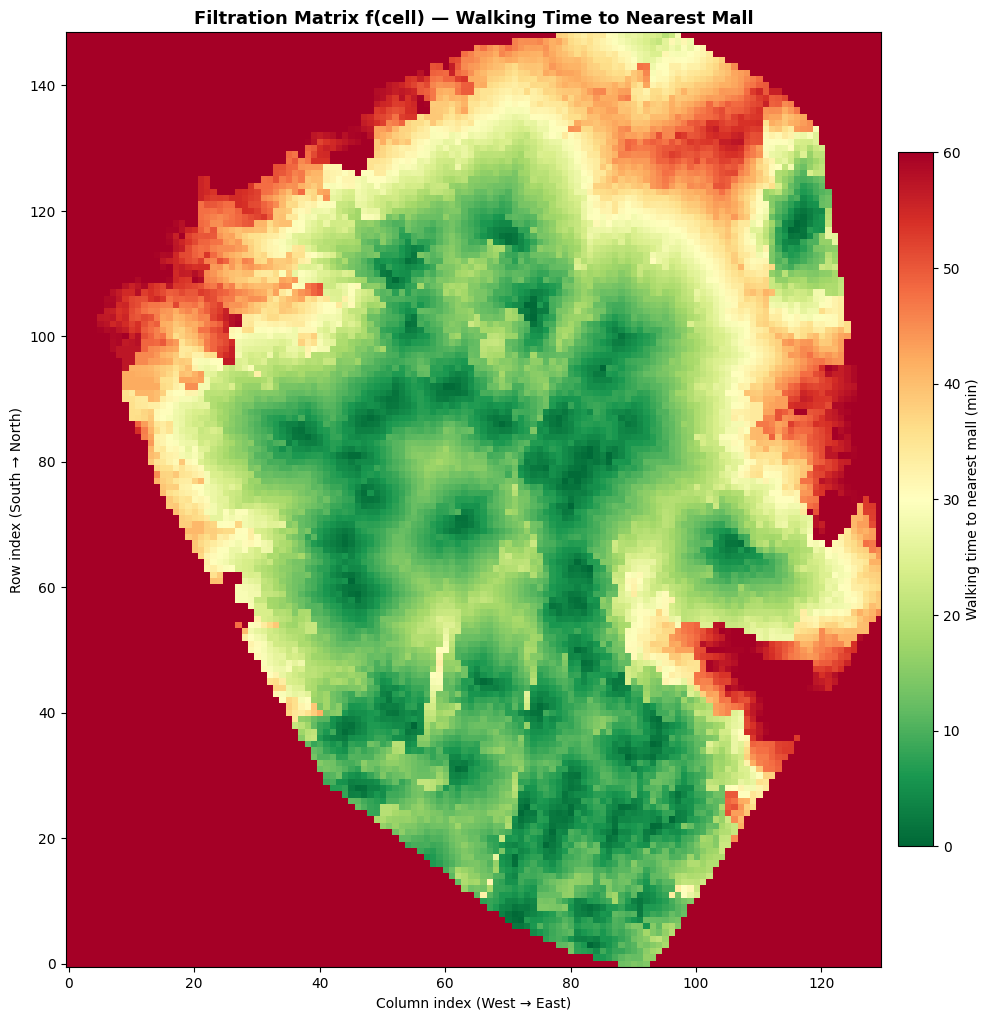

Saved fig04_filtration_matrix.png


In [28]:
# ── Plot: Filtration matrix as a heatmap ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 12))

im = ax.imshow(
    filtration_matrix,
    origin='lower',
    cmap='RdYlGn_r',
    vmin=0, vmax=60,
    interpolation='nearest'
)
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label('Walking time to nearest mall (min)', fontsize=10)

ax.set_title('Filtration Matrix f(cell) — Walking Time to Nearest Mall', fontsize=13, fontweight='bold')
ax.set_xlabel('Column index (West → East)')
ax.set_ylabel('Row index (South → North)')
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig04_filtration_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig04_filtration_matrix.png')

### 5.1 · Filtration snapshots — how $A_t$ evolves

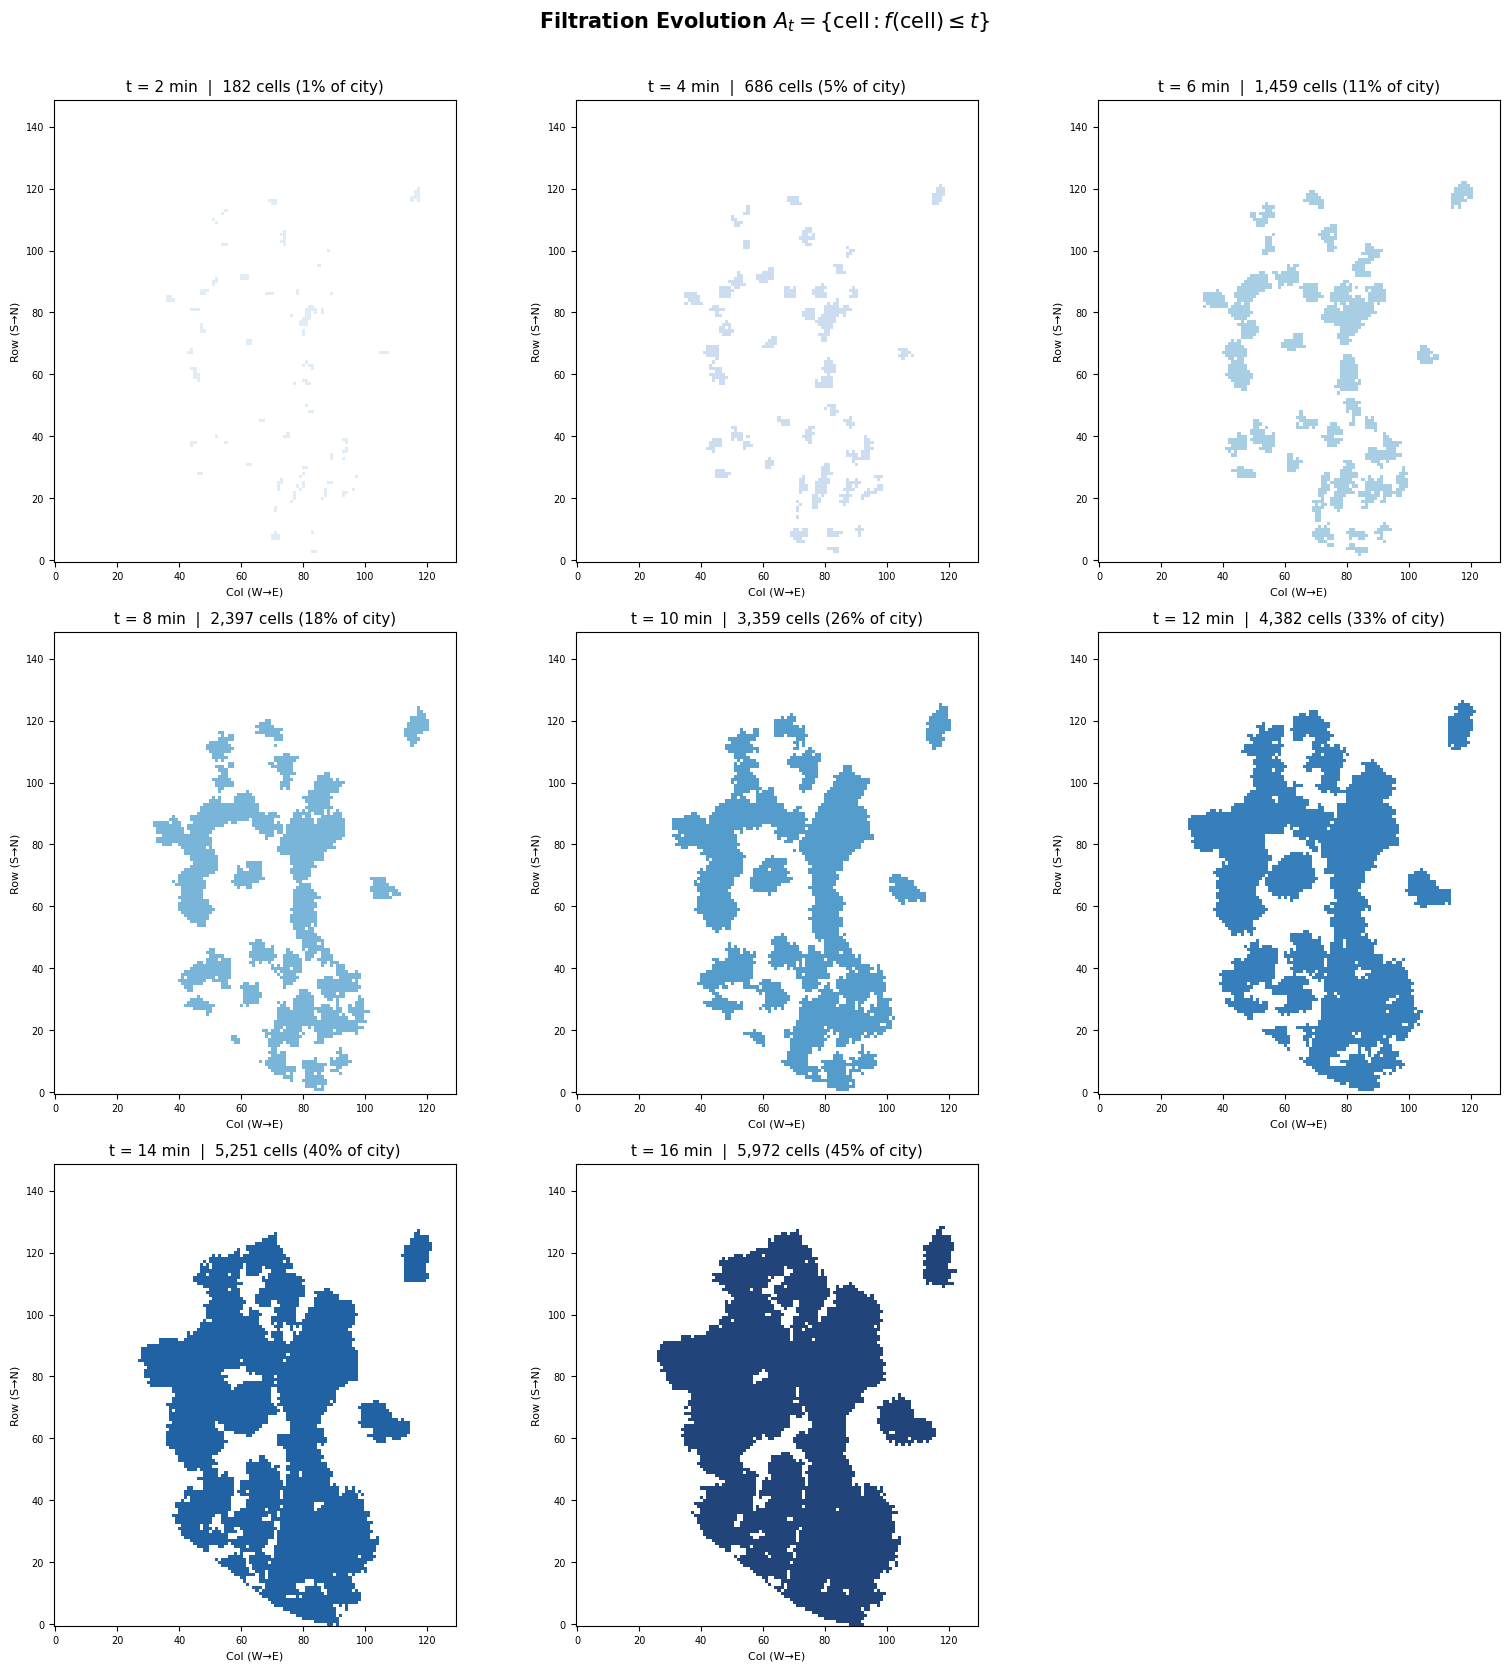

Saved fig05_filtration_snapshots.png


In [29]:
# ── Spatial maps of the sublevel sets at increasing thresholds ────────────────
THRESHOLDS = [2,4,6,8,10,12,14,16]
NCOLS = 3
NROWS = int(np.ceil(len(THRESHOLDS) / NCOLS))

fig, axes = plt.subplots(NROWS, NCOLS, figsize=(16, NROWS * 5.5))
axes = axes.flatten()

for i, t in enumerate(THRESHOLDS):
    ax = axes[i]

    # Binary mask: included at threshold t?
    included = filtration_matrix <= t
    disp = np.where(included, t, np.nan)

    ax.imshow(
        disp,
        origin='lower',
        cmap='Blues',
        vmin=0, vmax=max(THRESHOLDS),
        interpolation='nearest',
        alpha=0.9
    )

    pct = 100 * included.sum() / (filtration_matrix < SENTINEL).sum()
    ax.set_title(f't = {t} min  |  {included.sum():,} cells ({pct:.0f}% of city)', fontsize=11)
    ax.set_xlabel('Col (W→E)', fontsize=8)
    ax.set_ylabel('Row (S→N)', fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    r'Filtration Evolution $A_t = \{\\text{cell} : f(\\text{cell}) \\leq t\\}$',
    fontsize=15, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig05_filtration_snapshots.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig05_filtration_snapshots.png')

## 6 · Persistent Homology with GUDHI CubicalComplex

In [30]:
# ── Build the cubical complex ─────────────────────────────────────────────────
# GUDHI's CubicalComplex needs:
#   dimensions = [n_rows, n_cols]  (row-major)
#   top_dimensional_cells = flat list of cell filtration values

print('Building CubicalComplex …')
cc = gudhi.CubicalComplex(
    dimensions=list(filtration_matrix.shape),
    top_dimensional_cells=filtration_matrix.flatten().tolist()
)

print('Computing persistence …')
cc.compute_persistence()

persistence = cc.persistence()  # list of (dim, (birth, death))

# Separate by dimension
h0 = [(b, d) for dim, (b, d) in persistence if dim == 0]
h1 = [(b, d) for dim, (b, d) in persistence if dim == 1]

print(f'\n$H_0$ pairs: {len(h0)}  (connected components)')
print(f'$H_1$ pairs: {len(h1)}  (loops / holes)')

# Filter out the point at infinity for statistics
h0_finite = [(b, d) for b, d in h0 if d < SENTINEL]
h1_finite = [(b, d) for b, d in h1 if d < SENTINEL]
print(f'\nFinite $H_0$: {len(h0_finite)}')
print(f'Finite $H_1$: {len(h1_finite)}')

if h0_finite:
    persis0 = [d-b for b,d in h0_finite]
    print(f'$H_0$ persistence  mean={np.mean(persis0):.2f}  max={np.max(persis0):.2f} min')
if h1_finite:
    persis1 = [d-b for b,d in h1_finite]
    print(f'$H_1$ persistence  mean={np.mean(persis1):.2f}  max={np.max(persis1):.2f} min')

Building CubicalComplex …
Computing persistence …

$H_0$ pairs: 773  (connected components)
$H_1$ pairs: 382  (loops / holes)

Finite $H_0$: 757
Finite $H_1$: 333
$H_0$ persistence  mean=4.48  max=69.70 min
$H_1$ persistence  mean=2.79  max=23.10 min


In [31]:
# ── Most persistent H1 features (service voids) ──────────────────────────────
h1_sorted = sorted(h1_finite, key=lambda x: x[1]-x[0], reverse=True)
print('Top 15 most persistent H₁ features (service voids):')
print(f'{"Birth":>10}  {"Death":>10}  {"Persistence":>13}  Interpretation')
print('-' * 65)
for b, d in h1_sorted[:15]:
    pers = d - b
    born_at  = f'{b:.1f} min'
    dead_at  = f'{d:.1f} min'
    pers_str = f'{pers:.1f} min'
    # Interpret relative to the 15-min threshold
    if b > 15:
        note = 'void persists well beyond 15-min'
    elif d > 15:
        note = 'void crosses 15-min boundary'
    else:
        note = 'void resolved within 15 min'
    print(f'{born_at:>10}  {dead_at:>10}  {pers_str:>13}  {note}')

Top 15 most persistent H₁ features (service voids):
     Birth       Death    Persistence  Interpretation
-----------------------------------------------------------------
  34.6 min    57.7 min       23.1 min  void persists well beyond 15-min
  40.0 min    61.8 min       21.8 min  void persists well beyond 15-min
  32.6 min    48.5 min       15.9 min  void persists well beyond 15-min
  18.7 min    33.3 min       14.6 min  void persists well beyond 15-min
  17.3 min    31.7 min       14.4 min  void persists well beyond 15-min
  17.0 min    31.0 min       14.0 min  void persists well beyond 15-min
  22.9 min    36.8 min       13.9 min  void persists well beyond 15-min
  19.6 min    33.0 min       13.4 min  void persists well beyond 15-min
  18.7 min    32.0 min       13.3 min  void persists well beyond 15-min
  18.4 min    31.7 min       13.3 min  void persists well beyond 15-min
  17.5 min    30.4 min       12.9 min  void persists well beyond 15-min
  19.7 min    31.9 min       12.2 mi

In [32]:
# ── H0 analysis ──────────────────────────────────────────────────────────────
h0_sorted = sorted(h0_finite, key=lambda x: x[1]-x[0], reverse=True)
print(f'H₀ pairs (accessibility islands that eventually merge):')
print(f'  Born before 15 min and dying after 15 min: '
      f'{sum(1 for b,d in h0_finite if b <= 15 < d)}')
print(f'  Persistent beyond 30 min: '
      f'{sum(1 for b,d in h0_finite if d > 30)}')

H₀ pairs (accessibility islands that eventually merge):
  Born before 15 min and dying after 15 min: 72
  Persistent beyond 30 min: 93


## 7 · Visualise: Persistence Diagrams and Barcodes

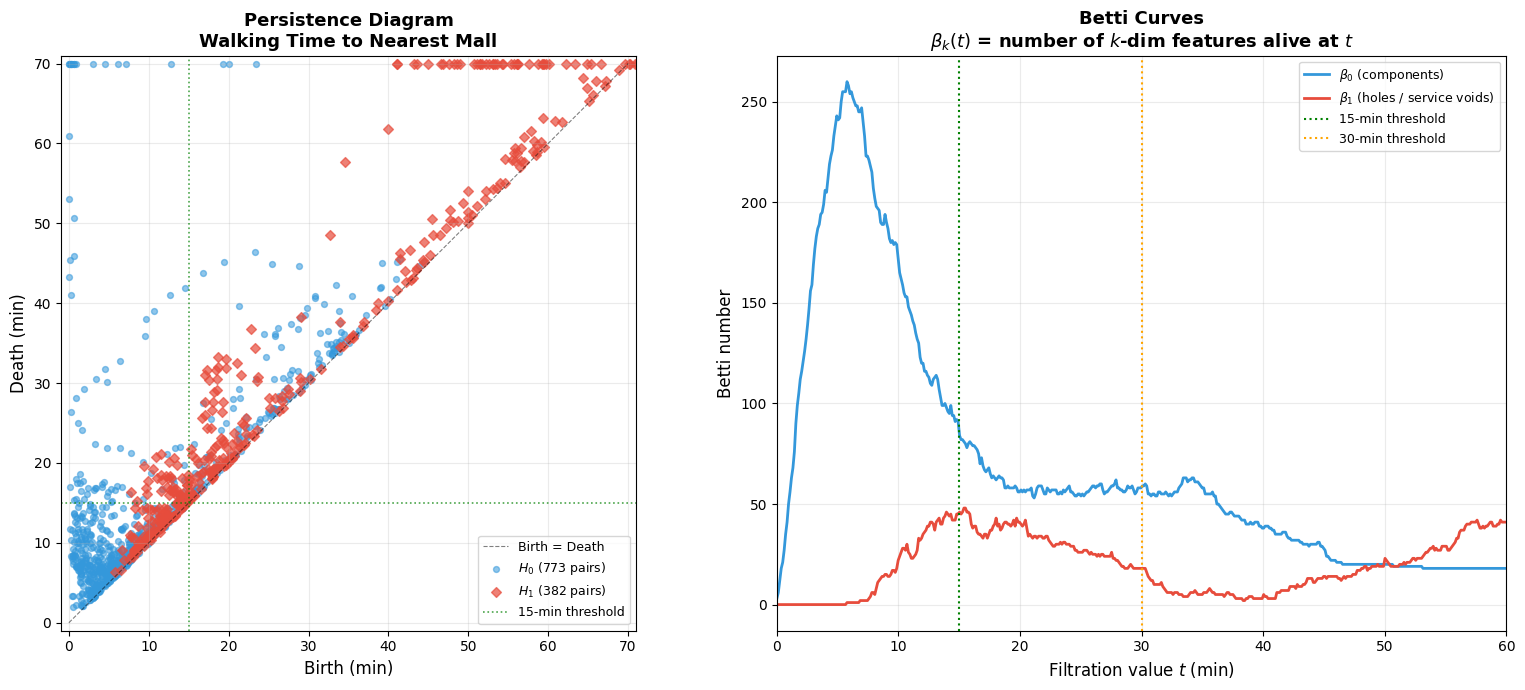

Saved fig06_persistence_diagram_betti.png


In [33]:
# ── Persistence diagram ───────────────────────────────────────────────────────
# Replace sentinel deaths with a finite display cap for plotting
PLOT_CAP = 70.0

def cap_persistence(pairs, cap=PLOT_CAP):
    return [(b, min(d, cap)) for b, d in pairs]

h0_plot = cap_persistence(h0)
h1_plot = cap_persistence(h1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Persistence diagram (manual, so we can style both dims together)
ax = axes[0]
lim = PLOT_CAP

# Diagonal
ax.plot([0, lim], [0, lim], 'k--', lw=0.8, alpha=0.5, label='Birth = Death')

# H0
births0, deaths0 = zip(*h0_plot) if h0_plot else ([], [])
ax.scatter(births0, deaths0, c='#3498db', s=18, alpha=0.55, label=f'$H_0$ ({len(h0)} pairs)')

# H1
if h1_plot:
    births1, deaths1 = zip(*h1_plot)
    ax.scatter(births1, deaths1, c='#e74c3c', s=25, alpha=0.7, marker='D',
               label=f'$H_1$ ({len(h1)} pairs)')

# 15-min reference lines
ax.axvline(15, color='green', ls=':', lw=1.2, alpha=0.7, label='15-min threshold')
ax.axhline(15, color='green', ls=':', lw=1.2, alpha=0.7)

ax.set_xlim(-1, lim + 1)
ax.set_ylim(-1, lim + 1)
ax.set_xlabel('Birth (min)', fontsize=12)
ax.set_ylabel('Death (min)', fontsize=12)
ax.set_title('Persistence Diagram\nWalking Time to Nearest Mall', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.set_aspect('equal')
ax.grid(True, alpha=0.25)

# ── Betti number curves ───────────────────────────────────────────────────────
ax2 = axes[1]
t_range = np.linspace(0, 60, 500)

def betti_curve(pairs, t_vals):
    """Count how many pairs have birth <= t < death."""
    counts = []
    for t in t_vals:
        c = sum(1 for b, d in pairs if b <= t < d)
        counts.append(c)
    return np.array(counts)

b0 = betti_curve(h0, t_range)
b1 = betti_curve(h1, t_range)

ax2.plot(t_range, b0, color='#3498db', lw=2.0, label='$\\beta_0$ (components)')
ax2.plot(t_range, b1, color='#e74c3c', lw=2.0, label='$\\beta_1$ (holes / service voids)')
ax2.axvline(15, color='green', ls=':', lw=1.5, label='15-min threshold')
ax2.axvline(30, color='orange', ls=':', lw=1.5, label='30-min threshold')

ax2.set_xlabel('Filtration value $t$ (min)', fontsize=12)
ax2.set_ylabel('Betti number', fontsize=12)
ax2.set_title('Betti Curves\n$\\beta_k(t)$ = number of $k$-dim features alive at $t$', fontsize=13, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.25)
ax2.set_xlim(0, 60)

plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig06_persistence_diagram_betti.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig06_persistence_diagram_betti.png')

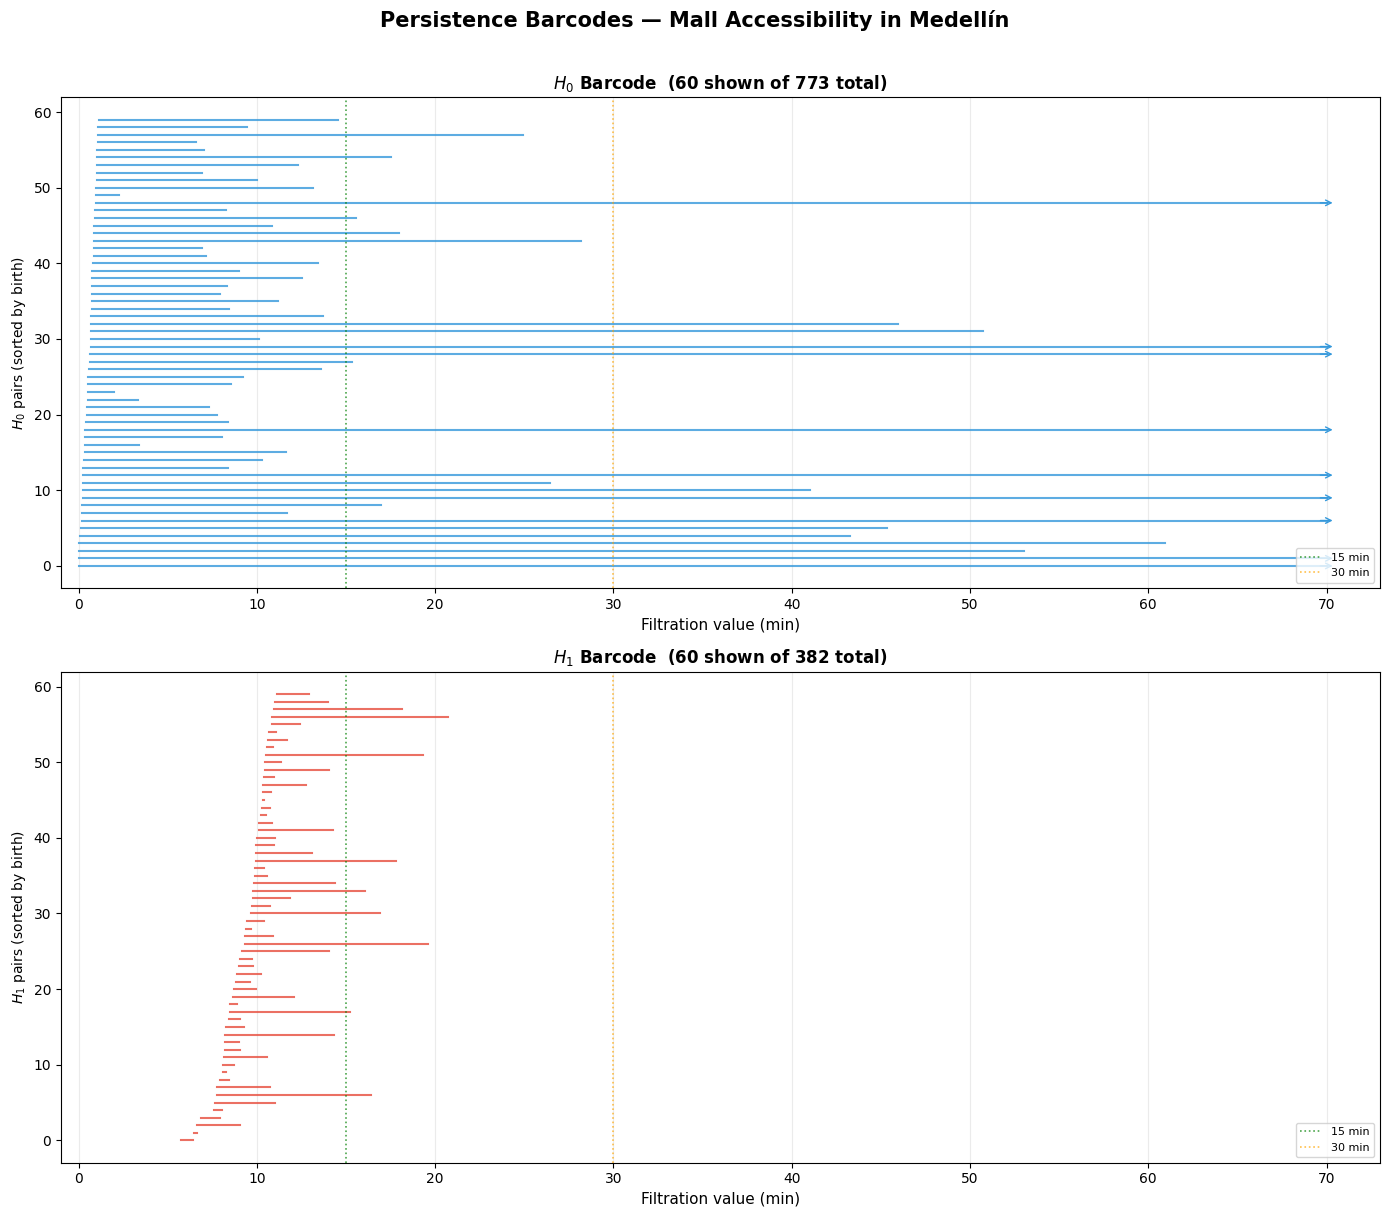

Saved fig07_barcodes.png


In [34]:
# ── Persistence Barcodes ──────────────────────────────────────────────────────
def plot_barcode(pairs, dim_label, color, ax, cap=PLOT_CAP, max_bars=80):
    """Draw a barcode for a list of (birth, death) pairs."""
    # Sort by birth, then persistence descending
    pairs_sorted = sorted(pairs, key=lambda x: (x[0], -(x[1]-x[0])))
    pairs_sorted = pairs_sorted[:max_bars]  # clip for readability

    for i, (b, d) in enumerate(pairs_sorted):
        d_plot = min(d, cap)
        ax.plot([b, d_plot], [i, i], color=color, lw=1.5, alpha=0.8)
        if d >= cap:
            ax.annotate('', xy=(cap + 0.5, i), xytext=(cap - 0.5, i),
                        arrowprops=dict(arrowstyle='->', color=color, lw=1.0))

    ax.axvline(15, color='green', ls=':', lw=1.2, alpha=0.7, label='15 min')
    ax.axvline(30, color='orange', ls=':', lw=1.2, alpha=0.7, label='30 min')
    ax.set_xlim(-1, cap + 3)
    ax.set_xlabel('Filtration value (min)', fontsize=11)
    ax.set_ylabel(f'{dim_label} pairs (sorted by birth)', fontsize=10)
    ax.set_title(f'{dim_label} Barcode  ({len(pairs_sorted)} shown of {len(pairs)} total)', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(axis='x', alpha=0.25)


fig, axes = plt.subplots(2, 1, figsize=(14, 12))
plot_barcode(h0, '$H_0$', '#3498db', axes[0], max_bars=60)
plot_barcode(h1, '$H_1$', '#e74c3c', axes[1], max_bars=60)

fig.suptitle('Persistence Barcodes — Mall Accessibility in Medellín', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig07_barcodes.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig07_barcodes.png')

## 8 · Topological Accessibility Indicators

We define three summary statistics inspired by the *Topological 15-Minute Score* proposed in the research framework.

In [ ]:
THRESHOLD = 15.0  # the 15-minute city benchmark

# ── H0 Fragmentation Index ────────────────────────────────────────────────────
# Number of H0 features that are still alive (not yet merged) at t=15 min
h0_alive_15 = [(b, d) for b, d in h0 if b <= THRESHOLD < d]
fragmentation_index = len(h0_alive_15)

# ── H1 Service-Void Index ─────────────────────────────────────────────────────
# Total persistence of H1 features that survive beyond the 15-min threshold
h1_beyond_15 = [(b, d) for b, d in h1 if d > THRESHOLD and d < SENTINEL]
service_void_index = sum(d - b for b, d in h1_beyond_15)

# ── Coverage at 15 min ────────────────────────────────────────────────────────
city_cells = (filtration_matrix < SENTINEL).sum()
covered_15 = (filtration_matrix <= THRESHOLD).sum()
coverage_pct = 100 * covered_15 / city_cells

print('=' * 55)
print('  TOPOLOGICAL ACCESSIBILITY INDICATORS (15-min city)')
print('=' * 55)
print(f'  Standard coverage (cells ≤ 15 min)     : {coverage_pct:.1f}%')
print(f'  H₀ Fragmentation Index (β₀ at t=15)    : {fragmentation_index}')
print(f'  H₁ Service-Void Index (Σ pers, t>15)   : {service_void_index:.1f} min')
print(f'  H₁ voids that cross 15-min boundary    : {len(h1_beyond_15)}')
print(f'  H₁ voids born after 15 min             : {sum(1 for b,d in h1 if b > 15 and d < SENTINEL)}')
print('=' * 55)

print(f'''
Interpretation
──────────────
• {coverage_pct:.0f}% of city grid cells are within 15 min of a mall.
• At t=15 min, β₀={fragmentation_index}: the 15-min accessible region consists of
  {fragmentation_index} disconnected islands. A truly integrated city would show β₀→1.
• {len(h1_beyond_15)} H₁ holes (service voids) persist beyond the 15-min mark,
  with total accumulated persistence of {service_void_index:.0f} minutes.
  These are regions ringed by accessible areas but themselves not reachable
  within 15 min — invisible to standard coverage metrics.
''')

In [ ]:
# ── Summary chart ─────────────────────────────────────────────────────────────
THRESHOLDS_EVAL = [5, 10, 15, 20, 25, 30]

cov    = [100 * (filtration_matrix <= t).sum() / city_cells for t in THRESHOLDS_EVAL]
beta0  = [betti_curve(h0, [t])[0] for t in THRESHOLDS_EVAL]
beta1  = [betti_curve(h1, [t])[0] for t in THRESHOLDS_EVAL]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(THRESHOLDS_EVAL, cov, color='#2ecc71', width=3.5, edgecolor='white')
axes[0].axvline(15, color='red', ls='--', lw=1.5)
axes[0].set_title('Standard Coverage\n% cells within t min', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Threshold t (min)')
axes[0].set_ylabel('Coverage (%)')
axes[0].set_ylim(0, 105)
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(THRESHOLDS_EVAL, beta0, 'o-', color='#3498db', lw=2, ms=7)
axes[1].axvline(15, color='red', ls='--', lw=1.5)
axes[1].set_title('$\\beta_0$ (Fragmentation Index)\n# accessible islands', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Threshold t (min)')
axes[1].set_ylabel('$\\beta_0$')
axes[1].grid(alpha=0.3)

axes[2].plot(THRESHOLDS_EVAL, beta1, 's-', color='#e74c3c', lw=2, ms=7)
axes[2].axvline(15, color='red', ls='--', lw=1.5)
axes[2].set_title('$\\beta_1$ (Service-Void Index)\n# holes / enclosed voids', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Threshold t (min)')
axes[2].set_ylabel('$\\beta_1$')
axes[2].grid(alpha=0.3)

for ax in axes:
    ax.set_xticks(THRESHOLDS_EVAL)

fig.suptitle('Coverage vs Topological Indicators — Mall Accessibility in Medellín', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig08_indicators.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig08_indicators.png')

## 9 · Service-Void Map (H₁ spatial localisation)

We identify the centroid of each significant H₁ void by finding, for each barcode interval $(b, d)$ with $d > 15$ min, the largest connected cluster of cells whose filtration value is in the range $[b, d]$ (the "donut" of cells that form the void boundary).  

A simpler and more robust proxy: highlight cells where $f(\text{cell})$ is in the range corresponding to the most persistent H₁ features.

In [ ]:
from scipy.ndimage import label as scipy_label

# ── For each significant H1 interval, mark cells in that birth-death range ───
# These are the "rim" cells that form or bound the topological void.

# Use top-10 most persistent H1 voids that survive past 15 min
top_voids = sorted(
    [(b, d) for b, d in h1 if d > 15 and d < SENTINEL],
    key=lambda x: x[1] - x[0], reverse=True
)[:10]

print(f'Top-10 H₁ service voids (persistence > 0, death > 15 min):')
for i, (b, d) in enumerate(top_voids):
    print(f'  Void {i+1:2d}: birth={b:.1f} min  death={d:.1f} min  persistence={d-b:.1f} min')

# Build a composite "void likelihood" map:
# a cell is highlighted if its filtration value falls in ANY top void's [b, d] range
void_map = np.zeros(filtration_matrix.shape, dtype=float)
for b, d in top_voids:
    in_range = (filtration_matrix >= b) & (filtration_matrix <= d)
    void_map += in_range.astype(float)

# Normalise
void_map = np.clip(void_map, 0, len(top_voids)) / max(len(top_voids), 1)

In [ ]:
# ── Plot: Walking-time map + void overlay ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Left: standard accessibility
ax = axes[0]
im0 = ax.imshow(
    np.where(filtration_matrix < SENTINEL, filtration_matrix, np.nan),
    origin='lower', cmap='RdYlGn_r', vmin=0, vmax=60, interpolation='nearest'
)
cbar0 = fig.colorbar(im0, ax=ax, fraction=0.04)
cbar0.set_label('Walking time (min)', fontsize=9)
ax.set_title('Standard Accessibility Map\nf(cell) = walking time to nearest mall', fontsize=12, fontweight='bold')
ax.set_xlabel('Col (W→E)')
ax.set_ylabel('Row (S→N)')

# Right: void overlay
ax2 = axes[1]
im_base = ax2.imshow(
    np.where(filtration_matrix <= 15, 1, np.nan),
    origin='lower', cmap='Greens', vmin=0, vmax=1.5, alpha=0.5, interpolation='nearest'
)
im_far = ax2.imshow(
    np.where((filtration_matrix > 15) & (filtration_matrix < SENTINEL), filtration_matrix, np.nan),
    origin='lower', cmap='Oranges', vmin=15, vmax=60, alpha=0.5, interpolation='nearest'
)
# Overlay void zones in strong red
im_void = ax2.imshow(
    np.where(void_map > 0, void_map, np.nan),
    origin='lower', cmap='Reds', vmin=0, vmax=1, alpha=0.75, interpolation='nearest'
)

# Legend patches
patches = [
    mpatches.Patch(color='#27ae60', alpha=0.7, label='Within 15 min (accessible)'),
    mpatches.Patch(color='#e67e22', alpha=0.7, label='15–60 min (limited access)'),
    mpatches.Patch(color='#c0392b', alpha=0.9, label='H₁ void zones (service deserts)'),
]
ax2.legend(handles=patches, loc='upper right', fontsize=8)
ax2.set_title('Topological Service Voids\nH₁ features with death > 15 min', fontsize=12, fontweight='bold')
ax2.set_xlabel('Col (W→E)')
ax2.set_ylabel('Row (S→N)')

fig.suptitle('Mall Accessibility in Medellín — Topological Perspective', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig09_void_map.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig09_void_map.png')

## 10 · Summary and Interpretation

This notebook demonstrates a complete proof-of-concept for applying **persistent homology** to the 15-minute city framework, using shopping malls in Medellín as the service layer.

### What the topology reveals

| Metric | Value | Meaning |
|--------|-------|---------|
| Standard coverage (≤15 min) | see cell above | % of city reachable within 15 min |
| β₀ at t=15 min (fragmentation) | see cell above | # disconnected accessibility islands |
| β₁ at t=15 min (service voids) | see cell above | # enclosed service voids at 15 min |
| H₁ voids persisting past 15 min | see cell above | voids invisible to coverage metrics |

### Topological interpretation

- **H₀ features** represent *fragmentation*: disconnected clusters of accessible cells. A large β₀ at t=15 min means the 15-minute city is not a single connected fabric but a collection of islands around malls.

- **H₁ features** represent *service voids*: holes in the accessibility surface — areas enclosed by accessible zones but themselves inaccessible within the threshold. These are the most novel finding; standard percentage coverage misses them entirely.

- **Betti curves** show how both types of features evolve as the threshold increases, revealing at which point the city starts to "connect" ($β_0 \to 1$) and when voids close ($β_1 \to 0$).

### Next steps for the thesis

1. **Slope-adjusted walking time**: replace Euclidean/OSRM times with slope-corrected Tobler function to capture Medellín's topography
2. **Multiple service types**: repeat for health centers, parks, schools
3. **Neighbourhood comparison**: compute topological indicators per *comuna* and correlate with socioeconomic strata
4. **Population weighting**: weight persistent features by residents inside each void
5. **Formal T₁₅ score**: $T_{15} = \alpha \cdot H_0^{>15} + \beta \cdot H_1^{>15}$

In [36]:
# Cache the walking-time grid so it does not need to be recomputed each run.
walking_time_mall_path = CITY_PH_ROOT / 'walking_time_mall.parquet'

if walking_time_mall_path.exists():
    grid_gdf = gpd.read_parquet(walking_time_mall_path)
    print(f'Loaded cached grid_gdf from {walking_time_mall_path}')
else:
    grid_gdf.to_parquet(walking_time_mall_path)
    print(f'Saved grid_gdf to {walking_time_mall_path}')

Saved grid_gdf to walking_time_mall.parquet
